In [1]:
import pyro
import torch
import torch.nn as nn
import torch.utils.data as data
import zuko
import matplotlib.pyplot as plt
import seaborn as sns
from pyro.contrib.zuko import ZukoToPyro
from pyro.optim import Adam
import numpy as np
from pyro.infer import SVI, Trace_ELBO
from torch import Tensor
from torchvision.datasets import MNIST
from torchvision.transforms.functional import to_tensor, to_pil_image
from tqdm import tqdm
from torch.utils.data import DataLoader, Dataset, TensorDataset

In [188]:
response_matrix_train = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Movies/CP/response_matrix_train.npy')
x = np.mean(response_matrix_train, axis = 0).reshape(-1, response_matrix_train.shape[3]).T
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
x = TSNE(n_components=2,perplexity = 1000).fit_transform(x)
my_dataset = TensorDataset(torch.tensor(x).float())  # create your datset
trainloader = DataLoader(my_dataset, batch_size=256,shuffle=True)

In [124]:
class GaussianEncoder(nn.Module):
    def __init__(self, features: int, latent: int):
        super().__init__()

        self.hyper = nn.Sequential(
            nn.Linear(features, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 2 * latent),
        )

    def forward(self, x: Tensor):
        phi = self.hyper(x)
        mu, log_sigma = phi.chunk(2, dim=-1)

        return pyro.distributions.Normal(mu, log_sigma.exp()).to_event(1)


class BernoulliDecoder(nn.Module):
    def __init__(self, features: int, latent: int):
        super().__init__()

        self.hyper = nn.Sequential(
            nn.Linear(2*latent, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, features),
        )

    def forward(self, x: Tensor):
        phi = self.hyper(x)
        mu, log_sigma = phi.chunk(2, dim=-1)

        return pyro.distributions.Normal(mu, log_sigma.exp()).to_event(1)

In [125]:
class VAE(nn.Module):
    def __init__(self, features: int, latent: int = 16):
        super().__init__()

        self.encoder = GaussianEncoder(features, latent)
        self.decoder = BernoulliDecoder(features, latent)

        self.prior = zuko.flows.MAF(
            features=latent,
            transforms=3,
            hidden_features=(256, 256),
        )

    def model(self, x: Tensor):
        pyro.module("prior", self.prior)
        pyro.module("decoder", self.decoder)

        with pyro.plate("batch", len(x)):
            z = pyro.sample("z", ZukoToPyro(self.prior()))
            x = pyro.sample("x", self.decoder(z), obs=x)

    def guide(self, x: Tensor):
        pyro.module("encoder", self.encoder)

        with pyro.plate("batch", len(x)):
            z = pyro.sample("z", self.encoder(x))

vae = VAE(20, 2)
vae

VAE(
  (encoder): GaussianEncoder(
    (hyper): Sequential(
      (0): Linear(in_features=20, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=32, bias=True)
      (3): ReLU()
      (4): Linear(in_features=32, out_features=4, bias=True)
    )
  )
  (decoder): BernoulliDecoder(
    (hyper): Sequential(
      (0): Linear(in_features=4, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=32, bias=True)
      (3): ReLU()
      (4): Linear(in_features=32, out_features=20, bias=True)
    )
  )
  (prior): MAF(
    (transform): LazyComposedTransform(
      (0): MaskedAutoregressiveTransform(
        (base): MonotonicAffineTransform()
        (order): [0, 1]
        (hyper): MaskedMLP(
          (0): MaskedLinear(in_features=2, out_features=256, bias=True)
          (1): ReLU()
          (2): MaskedLinear(in_features=256, out_features=256, bias=True)
          (3): ReLU()
          (4): MaskedLinear(in_features

In [126]:
pyro.clear_param_store()

svi = SVI(vae.model, vae.guide, Adam({'lr': 1e-3}), loss=Trace_ELBO())

for epoch in (bar := tqdm(range(1000))):
    losses = []

    for x in trainloader:
       # print(x.shape)
        x = x[0]
       # x = x.round().flatten(-3)

        losses.append(svi.step(x))

    losses = torch.tensor(losses)

    bar.set_postfix(loss=losses.sum().item() / len(trainset))

  0%|          | 0/1000 [00:00<?, ?it/s]


RuntimeError: mat1 and mat2 shapes cannot be multiplied (256x2 and 4x32)
                                Trace Shapes:          
                                 Param Sites:          
prior$$$transform.transforms.0.hyper.0.weight 256   2  
  prior$$$transform.transforms.0.hyper.0.bias     256  
prior$$$transform.transforms.0.hyper.2.weight 256 256  
  prior$$$transform.transforms.0.hyper.2.bias     256  
prior$$$transform.transforms.0.hyper.4.weight   4 256  
  prior$$$transform.transforms.0.hyper.4.bias       4  
prior$$$transform.transforms.1.hyper.0.weight 256   2  
  prior$$$transform.transforms.1.hyper.0.bias     256  
prior$$$transform.transforms.1.hyper.2.weight 256 256  
  prior$$$transform.transforms.1.hyper.2.bias     256  
prior$$$transform.transforms.1.hyper.4.weight   4 256  
  prior$$$transform.transforms.1.hyper.4.bias       4  
prior$$$transform.transforms.2.hyper.0.weight 256   2  
  prior$$$transform.transforms.2.hyper.0.bias     256  
prior$$$transform.transforms.2.

In [102]:
z = vae.prior().sample((10000,))
# x = vae.decoder(z).mean.reshape(-1, 28, 28)
#
# to_pil_image(x.movedim(0, 1).reshape(28, -1))

In [91]:
z.shape

torch.Size([10000, 2])

<Axes: xlabel='None', ylabel='None'>

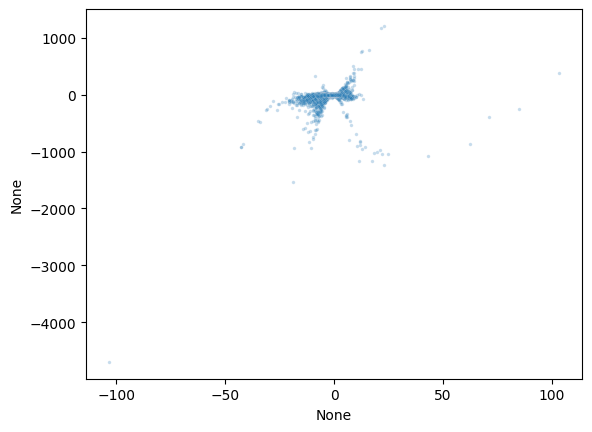

In [92]:
plt.figure()
sns.scatterplot(x = z[:,0], y = z[:,1],alpha = .25,s=6)

In [47]:
data.shape

AttributeError: module 'torch.utils.data' has no attribute 'shape'

In [176]:
import torch
import torch.nn as nn
import pyro
import pyro.distributions as dist

class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.fc = nn.Linear(input_dim, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x):
        h = torch.tanh(self.fc(x))
        z_mu = self.fc_mu(h)
        z_sigma = torch.exp(self.fc_logvar(h)) # Ensures positive scale
        return z_mu, z_sigma

class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim):
        super().__init__()
        self.fc = nn.Linear(latent_dim, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, output_dim)
        self.fc_logvar = nn.Linear(hidden_dim, output_dim)

    def forward(self, z):
        h = torch.tanh(self.fc(z))
        obs_mu = self.fc_mu(h)
        obs_sigma = torch.exp(self.fc_logvar(h)) # Scaled variance per feature
        return obs_mu, obs_sigma


In [177]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, latent_dim=2):
        super().__init__()
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim)
        self.latent_dim = latent_dim

    def model(self, x):
        pyro.module("decoder", self.decoder)
        with pyro.plate("data", x.shape[0]):
            # Prior p(z)
            z_loc = x.new_zeros(torch.Size((x.shape[0], self.latent_dim)))
            z_scale = x.new_ones(torch.Size((x.shape[0], self.latent_dim)))
            z = pyro.sample("latent", dist.Normal(z_loc, z_scale).to_event(1))

            # Normal Decoder p(x|z) with learned variance
            loc, scale = self.decoder(z)
            pyro.sample("obs", dist.Normal(loc, scale).to_event(1), obs=x)

    def guide(self, x):
        pyro.module("encoder", self.encoder)
        with pyro.plate("data", x.shape[0]):
            # Variational distribution q(z|x)
            z_loc, z_scale = self.encoder(x)
            pyro.sample("latent", dist.Normal(z_loc, z_scale).to_event(1))


In [178]:
from pyro.infer import SVI, Trace_ELBO
from pyro.optim import Adam

vae = VAE(input_dim=2) # Example dimension
optimizer = Adam({"lr": 1e-3})
svi = SVI(vae.model, vae.guide, optimizer, loss=Trace_ELBO())

# Typical training loop
# loss = svi.step(sensor_data_batch)


In [179]:
pyro.clear_param_store()


for epoch in (bar := tqdm(range(1000))):
    losses = []

    for x in trainloader:
       # print(x.shape)
        x = x[0]
       # x = x.round().flatten(-3)

        losses.append(svi.step(x))

    losses = torch.tensor(losses)

    bar.set_postfix(loss=losses.sum().item() / len(trainset))

100%|██████████| 1000/1000 [00:38<00:00, 26.21it/s, loss=0.506]


In [166]:
x.shape

torch.Size([188, 2])

In [185]:
z,_ = vae.encoder(torch.tensor(x).float())
z,_ = vae.decoder(z)

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_14892/3736423241.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  z,_ = vae.encoder(torch.tensor(x).float())


In [186]:
z.shape

torch.Size([188, 2])

<Axes: xlabel='None', ylabel='None'>

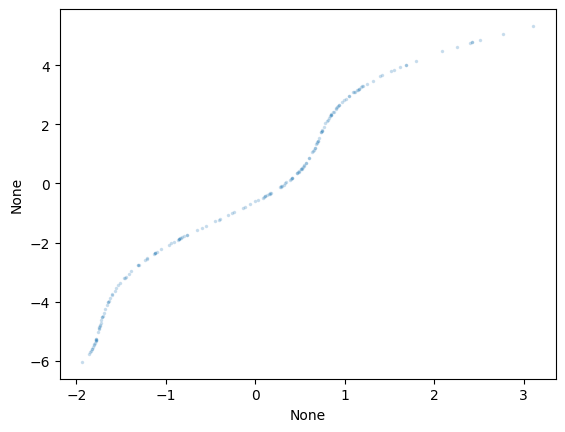

In [189]:
plt.figure()
sns.scatterplot(x = z[:,0].detach(), y = z[:,1].detach(),alpha = .25,s=6)

In [244]:
import pyro.distributions.transforms as T
import os
import numpy as np
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
smoke_test = ('CI' in os.environ)

n_samples = 1000
# X, y = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
# X = StandardScaler().fit_transform(X)
X = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/x_proj.npy')
X = torch.tensor(X)
base_dist = dist.Normal(torch.mean(X,axis=0), torch.std(X,axis=0))
spline_transform = T.spline_coupling(2, count_bins=20)
flow_dist = dist.TransformedDistribution(base_dist, [spline_transform])

In [249]:
steps = 1 if smoke_test else 5001
dataset = torch.tensor(X, dtype=torch.float)
optimizer = torch.optim.Adam(spline_transform.parameters(), lr=5e-3)
for step in range(20000):
    optimizer.zero_grad()
    loss = -flow_dist.log_prob(dataset).mean()
    loss.backward()
    optimizer.step()
    flow_dist.clear_cache()

    if step % 500 == 0:
        print('step: {}, loss: {}'.format(step, loss.item()))

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_14892/1704747387.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dataset = torch.tensor(X, dtype=torch.float)


step: 0, loss: 4.695223331451416
step: 500, loss: 4.69371223449707
step: 1000, loss: 4.738994121551514
step: 1500, loss: 4.818807125091553
step: 2000, loss: 4.693933486938477
step: 2500, loss: 4.744187355041504
step: 3000, loss: 4.749809265136719
step: 3500, loss: 4.727062225341797
step: 4000, loss: 4.7531514167785645
step: 4500, loss: 4.716503143310547
step: 5000, loss: 4.682730674743652
step: 5500, loss: 4.732851028442383
step: 6000, loss: 4.701437473297119
step: 6500, loss: 4.6854352951049805
step: 7000, loss: 4.6843132972717285
step: 7500, loss: 4.718776702880859
step: 8000, loss: 4.689339637756348
step: 8500, loss: 4.694467067718506
step: 9000, loss: 4.678008079528809
step: 9500, loss: 4.675228118896484
step: 10000, loss: 4.668797016143799
step: 10500, loss: 4.686939239501953
step: 11000, loss: 4.775981903076172
step: 11500, loss: 4.683534145355225
step: 12000, loss: 4.670194625854492
step: 12500, loss: 4.695945739746094
step: 13000, loss: 4.684038162231445
step: 13500, loss: 4.78

In [204]:
X

array('x_proj.npy', dtype='<U10')

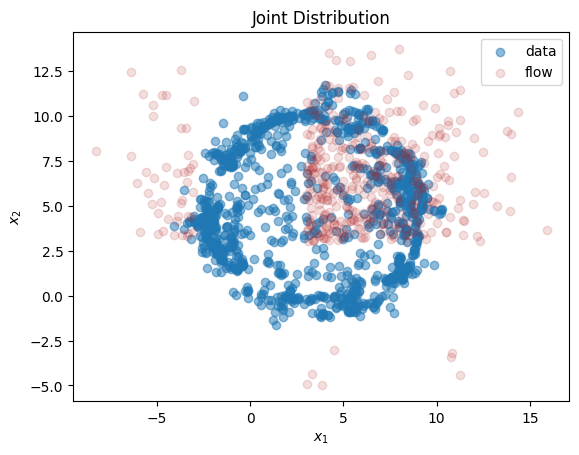

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_14892/1353135306.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X[:,0], hist=False, kde=True,
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_14892/1353135306.py:16: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns

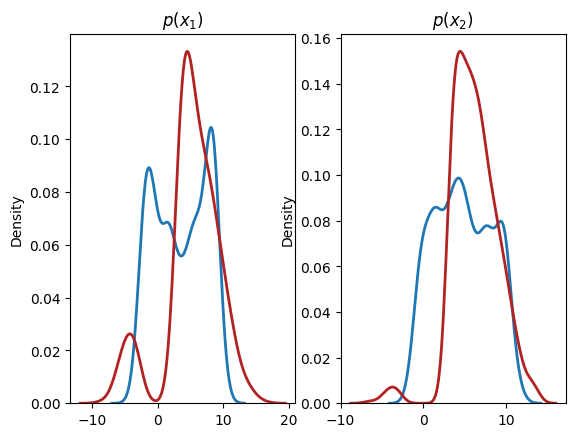

In [250]:
X_flow = flow_dist.sample(torch.Size([1000,])).detach().numpy()
plt.title(r'Joint Distribution')
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.scatter(X[:,0], X[:,1], label='data', alpha=0.5)
plt.scatter(X_flow[:,0], X_flow[:,1], color='firebrick', label='flow', alpha=0.15)
plt.legend()
plt.show()

plt.subplot(1, 2, 1)
sns.distplot(X[:,0], hist=False, kde=True,
             bins=None,
             hist_kws={'edgecolor':'black'},
             kde_kws={'linewidth': 2},
             label='data')
sns.distplot(X_flow[:,0], hist=False, kde=True,
             bins=None, color='firebrick',
             hist_kws={'edgecolor':'black'},
             kde_kws={'linewidth': 2},
             label='flow')
plt.title(r'$p(x_1)$')
plt.subplot(1, 2, 2)
sns.distplot(X[:,1], hist=False, kde=True,
             bins=None,
             hist_kws={'edgecolor':'black'},
             kde_kws={'linewidth': 2},
             label='data')
sns.distplot(X_flow[:,1], hist=False, kde=True,
             bins=None, color='firebrick',
             hist_kws={'edgecolor':'black'},
             kde_kws={'linewidth': 2},
             label='flow')
plt.title(r'$p(x_2)$')
plt.show()